# EDTA T-ECD (домен Retail)

In [107]:
import os
import glob
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

In [108]:
DATASET_PATH = '../../data/T_ECD_Project/raw_data/dataset/small'

## 1. Обзор данных

| Файл | Описание |
|-|-|
| users.pq | Пользователи |
| brands.pq | Бренды |
| retail/items.pq | Товары в категории ритейл |
| retail/events/{day}.pq | События в категории ритейл по дням |

### 1.1. Пользователи

In [109]:
df_users = pl.read_parquet(os.path.join(DATASET_PATH, 'users.pq'))
print(df_users.head(3))
print(f"Всего пользователей в таблице: {len(df_users)}")

shape: (3, 3)
┌──────────┬────────────────┬────────┐
│ user_id  ┆ socdem_cluster ┆ region │
│ ---      ┆ ---            ┆ ---    │
│ u64      ┆ u8             ┆ u8     │
╞══════════╪════════════════╪════════╡
│ 77309558 ┆ 21             ┆ 2      │
│ 72517894 ┆ 10             ┆ 90     │
│ 86699708 ┆ 9              ┆ 9      │
└──────────┴────────────────┴────────┘
Всего пользователей в таблице: 3500000


### 1.2. Бренды

In [110]:
df_brands = pl.read_parquet(os.path.join(DATASET_PATH, 'brands.pq'))
print(df_brands.head(3))
print(f"Всего товаров в таблице: {len(df_brands)}")

shape: (3, 2)
┌──────────┬─────────────────┐
│ brand_id ┆ embedding       │
│ ---      ┆ ---             │
│ u64      ┆ array[f32, 300] │
╞══════════╪═════════════════╡
│ 4        ┆ null            │
│ 34       ┆ null            │
│ 45       ┆ null            │
└──────────┴─────────────────┘
Всего товаров в таблице: 29485


### 1.3. Товары

In [111]:
df_retail = pl.read_parquet(os.path.join(DATASET_PATH, 'retail', 'items.pq'))
print(df_retail.head(3))
print(f"Всего товаров в таблице: {len(df_retail)}")

shape: (3, 6)
┌──────────────┬──────────┬────────────────────┬───────────────────┬───────────┬───────────────────┐
│ item_id      ┆ brand_id ┆ category           ┆ subcategory       ┆ price     ┆ embedding         │
│ ---          ┆ ---      ┆ ---                ┆ ---               ┆ ---       ┆ ---               │
│ str          ┆ u64      ┆ str                ┆ str               ┆ f64       ┆ array[f32, 300]   │
╞══════════════╪══════════╪════════════════════╪═══════════════════╪═══════════╪═══════════════════╡
│ fmcg_10      ┆ 65693    ┆ Office Supplies    ┆ Stationery Paper  ┆ -4.426084 ┆ [-0.135573,       │
│              ┆          ┆ and Educationa…    ┆                   ┆           ┆ 0.049446, …       │
│              ┆          ┆                    ┆                   ┆           ┆ 0.0231…           │
│ fmcg_10000   ┆ 146468   ┆ Cleaning Supplies  ┆ Cleaning and      ┆ -4.083248 ┆ [-0.043275,       │
│              ┆          ┆ and Everyday…      ┆ Detergent         ┆         

### 1.4. События

In [112]:
events_pattern = os.path.join(DATASET_PATH, 'retail', 'events', '*.pq')
events_path = os.path.join(DATASET_PATH, 'retail', 'events')
events_files = sorted(os.listdir(events_path))
total_events_files = len(events_files)

print(f"Всего файлов в папке events: {total_events_files}")

Всего файлов в папке events: 227


In [113]:
df_events_01082 = pl.read_parquet(os.path.join(DATASET_PATH, 'retail', 'events', '01082.pq'))
print(df_events_01082.head(3))
print(f"Данные за один день 01082: {len(df_events_01082)}")

shape: (3, 6)
┌────────────────┬──────────┬─────────────┬───────────┬─────────────┬─────────┐
│ timestamp      ┆ user_id  ┆ item_id     ┆ subdomain ┆ action_type ┆ os      │
│ ---            ┆ ---      ┆ ---         ┆ ---       ┆ ---         ┆ ---     │
│ duration[μs]   ┆ u64      ┆ str         ┆ str       ┆ str         ┆ str     │
╞════════════════╪══════════╪═════════════╪═══════════╪═════════════╪═════════╡
│ 1082d 188968µs ┆ 61870822 ┆ fmcg_292242 ┆ search    ┆ view        ┆ android │
│ 1082d 237416µs ┆ 6411253  ┆ fmcg_761291 ┆ catalog   ┆ view        ┆ android │
│ 1082d 240923µs ┆ 15367638 ┆ fmcg_830525 ┆ catalog   ┆ view        ┆ android │
└────────────────┴──────────┴─────────────┴───────────┴─────────────┴─────────┘
Данные за один день 01082: 387302


## 2. Пропуски

### 2.1. Пользователи

In [114]:
user_nulls = df_users.select([pl.col(c).null_count().alias(c) for c in df_users.columns])
print("Пропуски в users.pq:")
print(user_nulls)

user_nulls_length = len(df_users)

for col in df_users.columns:
    cnt = user_nulls[0, col]
    pct = (cnt / user_nulls_length) * 100
    print(f"  - {col}: {cnt:,} пропусков ({pct:.2f}%)")


Пропуски в users.pq:
shape: (1, 3)
┌─────────┬────────────────┬────────┐
│ user_id ┆ socdem_cluster ┆ region │
│ ---     ┆ ---            ┆ ---    │
│ u32     ┆ u32            ┆ u32    │
╞═════════╪════════════════╪════════╡
│ 0       ┆ 5153           ┆ 58917  │
└─────────┴────────────────┴────────┘
  - user_id: 0 пропусков (0.00%)
  - socdem_cluster: 5,153 пропусков (0.15%)
  - region: 58,917 пропусков (1.68%)


### 2.2. Бренды

In [115]:
brand_nulls = df_brands.select([pl.col(c).null_count().alias(c) for c in df_brands.columns])
print("Пропуски в users.pq:")
print(brand_nulls)

brand_nulls_length = len(df_brands)

for col in df_brands.columns:
    cnt = brand_nulls[0, col]
    pct = (cnt / brand_nulls_length) * 100
    print(f"  - {col}: {cnt:,} пропусков ({pct:.2f}%)")

Пропуски в users.pq:
shape: (1, 2)
┌──────────┬───────────┐
│ brand_id ┆ embedding │
│ ---      ┆ ---       │
│ u32      ┆ u32       │
╞══════════╪═══════════╡
│ 0        ┆ 22437     │
└──────────┴───────────┘
  - brand_id: 0 пропусков (0.00%)
  - embedding: 22,437 пропусков (76.10%)


### 2.3. Товары

Анализ пропусков в Retail Items:
  - item_id: 0 пропусков (0.00%)
  - brand_id: 0 пропусков (0.00%)
  - category: 9,615 пропусков (3.83%)
  - subcategory: 9,615 пропусков (3.83%)
  - price: 725 пропусков (0.29%)
  - embedding: 0 пропусков (0.00%)


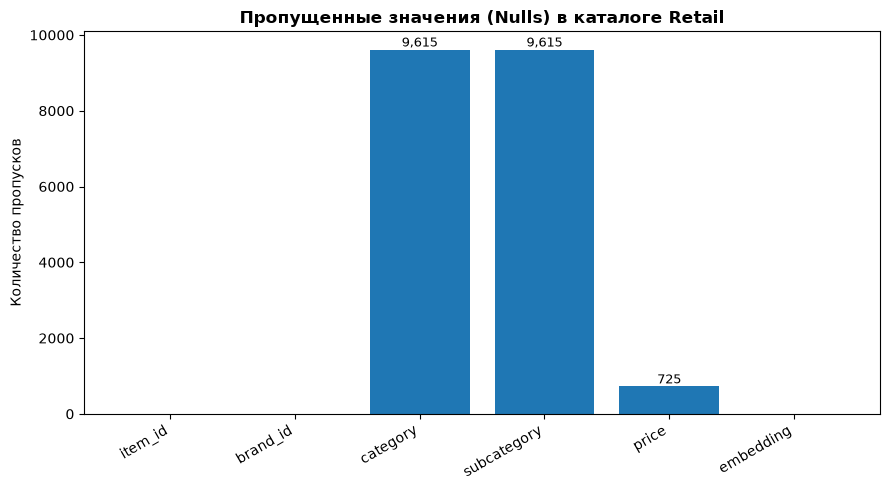

In [116]:
# 1. Считаем количество пропусков по каждому столбцу
null_counts_df = df_retail.select([pl.col(c).null_count().alias(c) for c in df_retail.columns])
null_counts_dict = null_counts_df.row(0, named=True)

# 2. Выводим текстовый отчет с процентами
print("Анализ пропусков в Retail Items:")
total_rows = len(df_retail)
for col, count in null_counts_dict.items():
    pct = (count / total_rows) * 100
    print(f"  - {col}: {count:,} пропусков ({pct:.2f}%)")

# 3. Строим диаграмму
cols = list(null_counts_dict.keys())
counts = list(null_counts_dict.values())

plt.figure(figsize=(9, 5))
bars = plt.bar(cols, counts)

plt.title('Пропущенные значения (Nulls) в каталоге Retail', fontsize=12, fontweight='bold')
plt.ylabel('Количество пропусков')
plt.xticks(rotation=30, ha='right')

# Подписываем точные значения над столбцами, где пропуски есть
for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,}',
                 ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### 2.4. События

In [117]:
lazy_events = pl.scan_parquet(events_pattern)

null_stats = lazy_events.select(
    [pl.len().alias('total_rows')] +
    [pl.col(col).null_count().alias(f"{col}_nulls") for col in lazy_events.collect_schema().names()]
).collect()

print("Результаты проверки пропусков в событиях:")
print(null_stats)

Результаты проверки пропусков в событиях:
shape: (1, 7)
┌────────────┬──────────────┬──────────────┬──────────────┬──────────────┬──────────────┬──────────┐
│ total_rows ┆ timestamp_nu ┆ user_id_null ┆ item_id_null ┆ subdomain_nu ┆ action_type_ ┆ os_nulls │
│ ---        ┆ lls          ┆ s            ┆ s            ┆ lls          ┆ nulls        ┆ ---      │
│ u32        ┆ ---          ┆ ---          ┆ ---          ┆ ---          ┆ ---          ┆ u32      │
│            ┆ u32          ┆ u32          ┆ u32          ┆ u32          ┆ u32          ┆          │
╞════════════╪══════════════╪══════════════╪══════════════╪══════════════╪══════════════╪══════════╡
│ 267043972  ┆ 0            ┆ 0            ┆ 0            ┆ 0            ┆ 0            ┆ 0        │
└────────────┴──────────────┴──────────────┴──────────────┴──────────────┴──────────────┴──────────┘


## 3. Дублиткаты

### 3.1. Пользователи

In [118]:
total_rows = len(df_users)
unique_items = df_users.select(pl.col('user_id').n_unique()).item()

print(f"Всего строк в users.pq: {total_rows:,}")
print(f"Уникальных user_id: {unique_items:,}")

if total_rows == unique_items:
    print("Дубликатов по user_id нет — ключи полностью уникальны.")
else:
    print(f"Дубликатов по user_id: {total_rows - unique_items:,}")

exact_duplicates = df_users.is_duplicated().sum()
print(f"Количество полностью дублирующихся строк: {exact_duplicates:,}")

if exact_duplicates > 0:
    print("\nПримеры дубликатов:")
    print(df_users.filter(df_users.is_duplicated()).head(5))

Всего строк в users.pq: 3,500,000
Уникальных user_id: 3,500,000
Дубликатов по user_id нет — ключи полностью уникальны.
Количество полностью дублирующихся строк: 0


### 3.2. Бренды

In [119]:
total_rows = len(df_brands)
unique_items = df_brands.select(pl.col('brand_id').n_unique()).item()

print(f"Всего строк в brands.pq: {total_rows:,}")
print(f"Уникальных brand_id: {unique_items:,}")

if total_rows == unique_items:
    print("Дубликатов по brand_id нет — ключи полностью уникальны.")
else:
    print(f"Дубликатов по brand_id: {total_rows - unique_items:,}")

exact_duplicates = df_brands.is_duplicated().sum()
print(f"Количество полностью дублирующихся строк: {exact_duplicates:,}")

if exact_duplicates > 0:
    print("\nПримеры дубликатов:")
    print(df_brands.filter(df_brands.is_duplicated()).head(5))

Всего строк в brands.pq: 29,485
Уникальных brand_id: 29,453
Дубликатов по brand_id: 32
Количество полностью дублирующихся строк: 0


In [120]:
duplicate_brands = df_brands.filter(pl.col('brand_id').is_duplicated()).sort('brand_id')

print(f"Всего строк с дублирующимся brand_id: {len(duplicate_brands):,}")
print("Примеры конфликтующих строк:")
print(duplicate_brands.head(10))

Всего строк с дублирующимся brand_id: 37
Примеры конфликтующих строк:
shape: (10, 2)
┌──────────┬─────────────────────────────────┐
│ brand_id ┆ embedding                       │
│ ---      ┆ ---                             │
│ u64      ┆ array[f32, 300]                 │
╞══════════╪═════════════════════════════════╡
│ 37799    ┆ [-0.104787, 0.0138, … 0.068517… │
│ 37799    ┆ [-0.101765, 0.001566, … 0.0892… │
│ 37799    ┆ [-0.088603, 0.040422, … 0.0835… │
│ 37799    ┆ null                            │
│ 37799    ┆ [-0.081444, 0.028631, … 0.0801… │
│ 37799    ┆ [-0.095465, 0.006346, … 0.0733… │
│ 60434    ┆ [-0.096083, 0.039856, … 0.0825… │
│ 60434    ┆ [-0.081872, 0.036504, … 0.0817… │
│ 60434    ┆ [-0.086953, 0.051163, … 0.0864… │
│ 60434    ┆ [-0.084061, 0.029767, … 0.1041… │
└──────────┴─────────────────────────────────┘


В датасете `brands.pq` 32 дубликата по brand_id при том, что полностью идентичных строк нет. Возможно эмбеддинги бренда агрегировались в разное время или с разной выборкой.

Самый надежный способ очистки — очистить от null и усреднить векторы (получить центроид бренда) или просто оставить первую валидную запись. Усреднение векторов работает лучше всего, так как сглаживает выбросы.

### 3.3. Товары

In [121]:
total_rows = len(df_retail)
unique_items = df_retail.select(pl.col('item_id').n_unique()).item()

print(f"Всего строк в items.pq: {total_rows:,}")
print(f"Уникальных item_id: {unique_items:,}")

if total_rows == unique_items:
    print("Дубликатов по item_id нет — ключи полностью уникальны.")
else:
    print(f"Дубликатов по item_id: {total_rows - unique_items:,}")

exact_duplicates = df_retail.is_duplicated().sum()
print(f"Количество полностью дублирующихся строк: {exact_duplicates:,}")

if exact_duplicates > 0:
    print("\nПримеры дубликатов:")
    print(df_retail.filter(df_retail.is_duplicated()).head(5))

Всего строк в items.pq: 250,856
Уникальных item_id: 250,856
Дубликатов по item_id нет — ключи полностью уникальны.
Количество полностью дублирующихся строк: 0


### 3.4. События

In [122]:
total_rows_found = 0
total_dups_found = 0

for i, file_name in enumerate(events_files):
    file_path = os.path.join(events_path, file_name)

    row_count = (
        pl.scan_parquet(file_path)
        .select(pl.len())
        .collect()
        .item()
    )
    total_rows_found += row_count

    dup_count = (
        pl.scan_parquet(file_path)
        .filter(
            pl.struct(['timestamp', 'user_id', 'item_id', 'action_type'])
            .is_duplicated()
        )
        .select(pl.len())
        .collect()
        .item()
    )

    total_dups_found += dup_count

print(f"Всего событий в файлах: {total_rows_found:,}")
print(f"Всего дубликатов в файлах событий: {total_dups_found:,}")

Всего событий в файлах: 267,043,972
Всего дубликатов в файлах событий: 10


Датасет с событиями обладает хорошим качеством. 

Кол-во дубликатов - 10 штук, не внесет заметной погрешности в предсказание модели.

## 4. Обзор признаков

### 4.1. Пользователи

In [123]:
unique_event_users = lazy_events.select(pl.col('user_id')).unique().collect().get_column('user_id')
catalog_users = df_users.get_column('user_id')

orphaned_event_users = unique_event_users.filter(~unique_event_users.is_in(catalog_users.implode()))
print(f"Уникальных пользователей в событиях: {len(unique_event_users):,}")
print(f"Пользователей из событий, отсутствующих в users.pq: {len(orphaned_event_users):,}")

Уникальных пользователей в событиях: 140,062
Пользователей из событий, отсутствующих в users.pq: 0


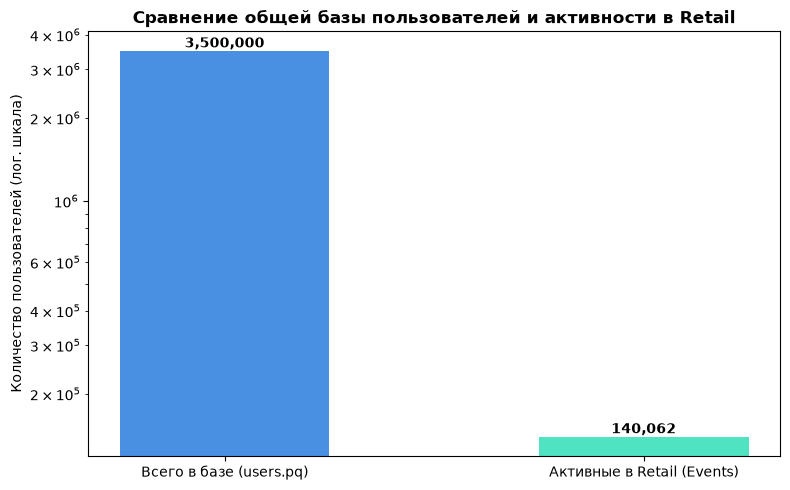

In [124]:
total_users = len(df_users)
retail_active_users = len(unique_event_users)

categories = ['Всего в базе (users.pq)', 'Активные в Retail (Events)']
counts = [total_users, retail_active_users]

plt.figure(figsize=(8, 5))
bars = plt.bar(categories, counts, color=['#4A90E2', '#50E3C2'], width=0.5)

plt.title('Сравнение общей базы пользователей и активности в Retail', fontsize=12, fontweight='bold')
plt.ylabel('Количество пользователей')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.yscale('log')
plt.ylabel('Количество пользователей (лог. шкала)')

plt.tight_layout()
plt.show()

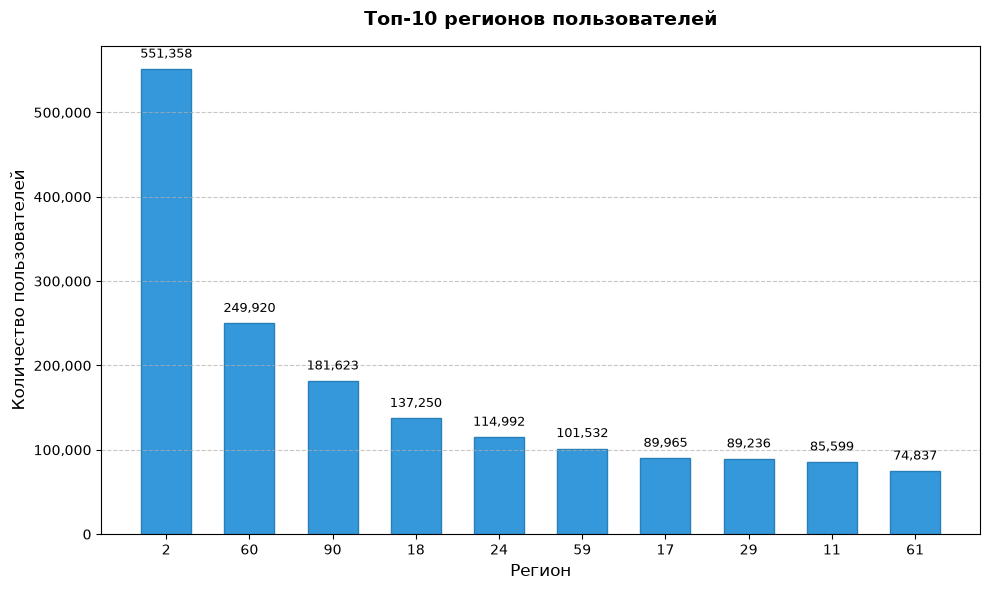

In [125]:
top_regions = df_users.group_by('region').len().sort('len', descending=True)

df_plot = top_regions.head(10).to_pandas()

regions = df_plot['region'].astype(str)
counts = df_plot['len']

plt.figure(figsize=(10, 6))
bars = plt.bar(regions, counts, color='#3498db', edgecolor='#2980b9', width=0.6)

plt.title('Топ-10 регионов пользователей', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Регион', fontsize=12)
plt.ylabel('Количество пользователей', fontsize=12)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.,
        height + 10000,
        f"{height:,.0f}",
        ha='center',
        va='bottom',
        fontsize=9,
        rotation=0
    )

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

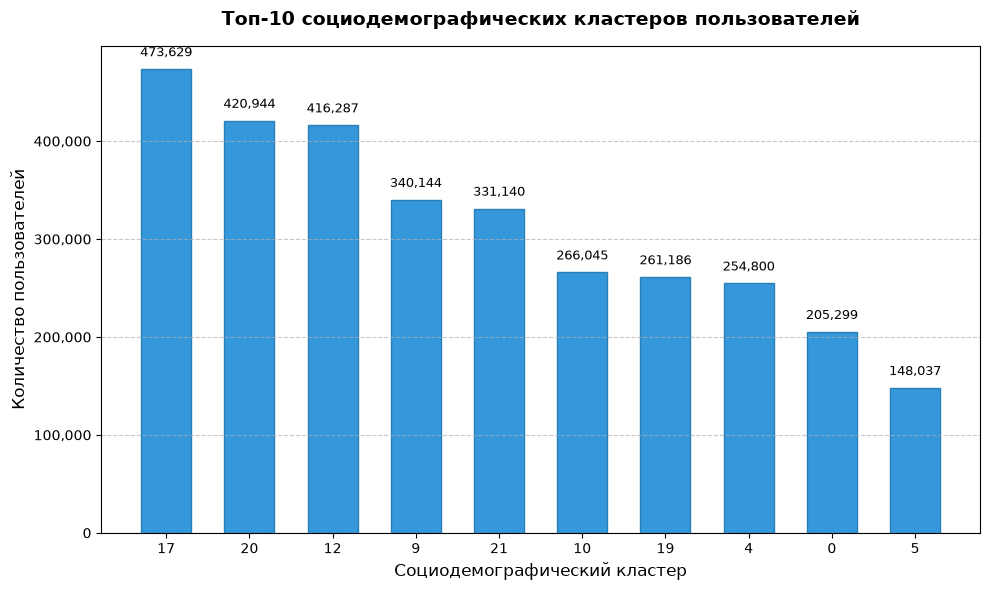

In [126]:
top_clusters = df_users.group_by('socdem_cluster').len().sort('len', descending=True)

df_plot = top_clusters.head(10).to_pandas()

clusters = df_plot['socdem_cluster'].astype(str)
counts = df_plot['len']

plt.figure(figsize=(10, 6))
bars = plt.bar(clusters, counts, color='#3498db', edgecolor='#2980b9', width=0.6)

plt.title('Топ-10 социодемографических кластеров пользователей', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Социодемографический кластер', fontsize=12)
plt.ylabel('Количество пользователей', fontsize=12)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

# Подписываем значения прямо над столбиками
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.,
        height + 10000,
        f"{height:,.0f}",
        ha='center',
        va='bottom',
        fontsize=9,
        rotation=0
    )

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Показываем график
plt.show()

### 4.2. Бренды

In [127]:
retail_brands = df_retail.select(pl.col('brand_id').unique()).get_column('brand_id')
print(f"Всего уникальных брендов в товарах ритейла (items.pq): {len(retail_brands):,}")

catalog_brands = df_brands.get_column('brand_id')

in_retail_not_in_catalog = df_retail.filter(~pl.col('brand_id').is_in(list(catalog_brands)))
print(f"Товары, ссылающиеся на несуществующие в справочнике бренды: {len(in_retail_not_in_catalog):,}")

Всего уникальных брендов в товарах ритейла (items.pq): 8
Товары, ссылающиеся на несуществующие в справочнике бренды: 0


### 4.3. Товары

In [128]:
existing_items_set = set(df_retail.get_column("item_id").to_list())
total_in_catalog = len(existing_items_set)

unique_events_items = (
    lazy_events
    .select('item_id')
    .unique()
    .collect()
    .get_column('item_id')
    .to_list()
)

total_in_events = len(unique_events_items)

# Считаем пересечения
events_items_set = set(unique_events_items)
found_in_catalog = events_items_set.intersection(existing_items_set)
missing_from_catalog = events_items_set.difference(existing_items_set)

cnt_found = len(found_in_catalog)
cnt_missing = len(missing_from_catalog)

# Считаем проценты относительно уникальных товаров в событиях
pct_found = (cnt_found / total_in_events) * 100 if total_in_events > 0 else 0
pct_missing = (cnt_missing / total_in_events) * 100 if total_in_events > 0 else 0

print(f"Всего уникальных товаров в items.pq: {total_in_catalog:,}")
print(f"Всего уникальных товаров в events: {total_in_events:,}")

print(f"Присутствуют в items.pq:  {cnt_found:>10,} ({pct_found:6.2f}%)")
print(f"Отсутствуют в events:  {cnt_missing:>10,} ({pct_missing:6.2f}%)")


Всего уникальных товаров в items.pq: 250,856
Всего уникальных товаров в events: 257,327
Присутствуют в items.pq:     248,806 ( 96.69%)
Отсутствуют в events:       8,521 (  3.31%)


Есть события по товарам, которые отсутствуют в датасете items.pq. Их необходимо отфильтровывать в процессе тренировки модели.

### 4.4. События

In [129]:
subdomains = lazy_events.select(pl.col('subdomain').unique()).collect().get_column('subdomain').to_list()
action_types = lazy_events.select(pl.col('action_type').unique()).collect().get_column('action_type').to_list()
os_types = lazy_events.select(pl.col('os').unique()).collect().get_column('os').to_list()

print(f"subdomain: {subdomains}")
print(f"action_type: {action_types}")
print(f"os: {os_types}")

subdomain: ['i2i', 'catalog', 'other', 'main', 'search']
action_type: ['view', 'added_to_cart', 'click', 'order']
os: ['other', 'android', 'ios']


In [130]:
subdomain_counts = lazy_events.group_by('subdomain').len().sort('len', descending=True).collect()

print("Статистика событий по subdomain:")
print(subdomain_counts)

Статистика событий по subdomain:
shape: (5, 2)
┌───────────┬───────────┐
│ subdomain ┆ len       │
│ ---       ┆ ---       │
│ str       ┆ u32       │
╞═══════════╪═══════════╡
│ catalog   ┆ 231285386 │
│ search    ┆ 21575005  │
│ other     ┆ 7433721   │
│ main      ┆ 3804123   │
│ i2i       ┆ 2945737   │
└───────────┴───────────┘


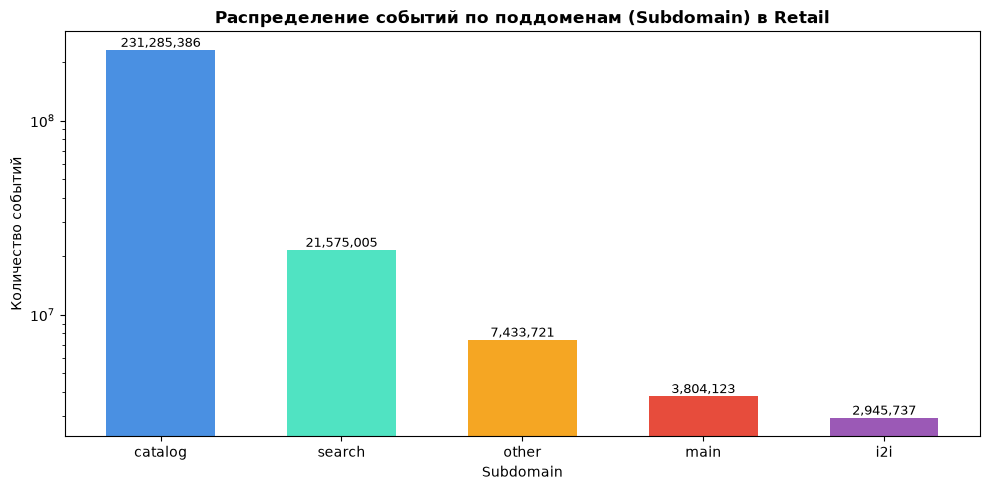

In [131]:
subdomains = subdomain_counts.get_column('subdomain').to_list()
counts = subdomain_counts.get_column('len').to_list()

colors = ['#4A90E2', '#50E3C2', '#F5A623', '#E74C3C', '#9B59B6']

plt.figure(figsize=(10, 5))
bars = plt.bar(subdomains, counts, color=colors[:len(subdomains)], width=0.6)

plt.title('Распределение событий по поддоменам (Subdomain) в Retail', fontsize=12, fontweight='bold')
plt.ylabel('Количество событий')
plt.yscale('log')
plt.xlabel('Subdomain')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,.0f}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [132]:
action_type_counts = lazy_events.group_by('action_type').len().sort('len', descending=True).collect()

print("Статистика событий по action_type:")
print(action_type_counts)

Статистика событий по action_type:
shape: (4, 2)
┌───────────────┬───────────┐
│ action_type   ┆ len       │
│ ---           ┆ ---       │
│ str           ┆ u32       │
╞═══════════════╪═══════════╡
│ view          ┆ 253468410 │
│ order         ┆ 7433721   │
│ added_to_cart ┆ 3852145   │
│ click         ┆ 2289696   │
└───────────────┴───────────┘


Просмотров - 253 468 410

Заказов - 7 433 721

Добавлено в корзину - 3 852 145

Кликов - 2 289 696

В ритейле заказов больше чем добавлений в корзину и кликов.

Строить классическую продуктовую воронку конверсий (view -> click -> cart -> order) по этим цифрам бесполезно и некорректно.

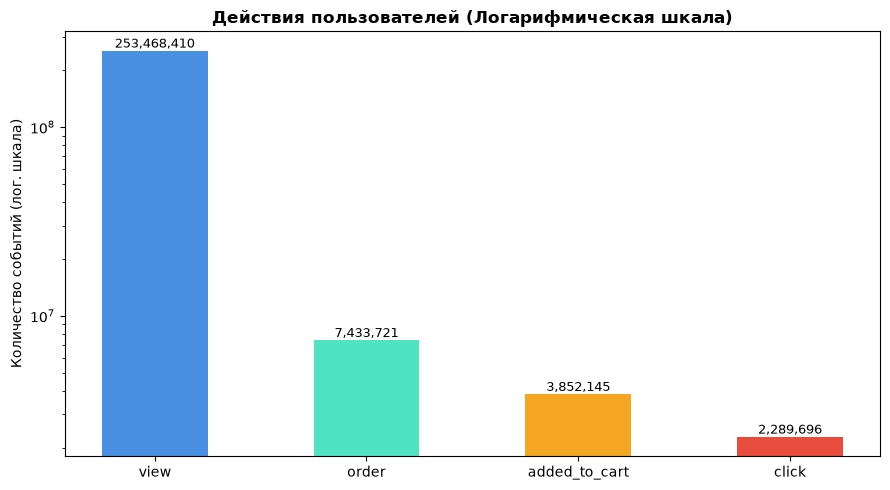

In [133]:
actions = action_type_counts.get_column('action_type').to_list()
counts = action_type_counts.get_column('len').to_list()

plt.figure(figsize=(9, 5))
bars = plt.bar(actions, counts, color=['#4A90E2', '#50E3C2', '#F5A623', '#E74C3C'], width=0.5)

plt.title('Действия пользователей (Логарифмическая шкала)', fontsize=12, fontweight='bold')
plt.ylabel('Количество событий (лог. шкала)')
plt.yscale('log')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,.0f}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


In [134]:
os_counts = lazy_events.group_by('os').len().sort('len', descending=True).collect()

print("Статистика событий по os:")
print(os_counts)

Статистика событий по os:
shape: (3, 2)
┌─────────┬───────────┐
│ os      ┆ len       │
│ ---     ┆ ---       │
│ str     ┆ u32       │
╞═════════╪═══════════╡
│ android ┆ 242432816 │
│ ios     ┆ 22007523  │
│ other   ┆ 2603633   │
└─────────┴───────────┘


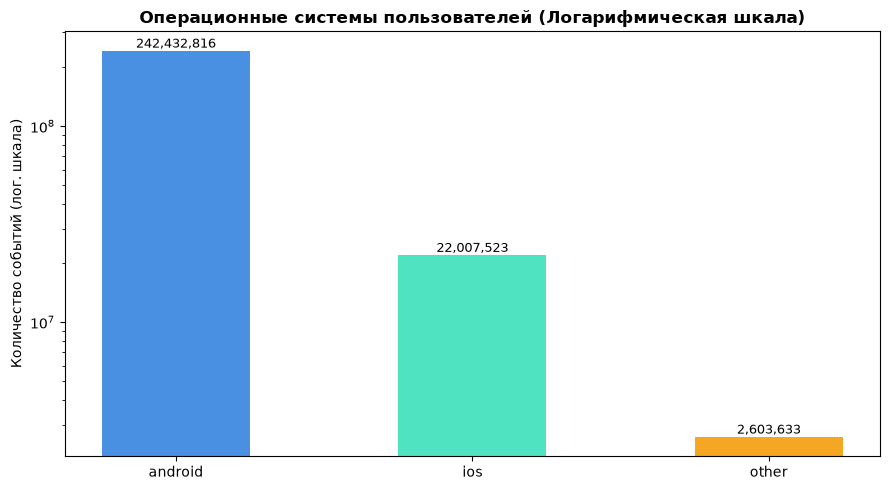

In [135]:
os_names = os_counts.get_column('os').to_list()
counts = os_counts.get_column('len').to_list()

plt.figure(figsize=(9, 5))
bars = plt.bar(os_names, counts, color=['#4A90E2', '#50E3C2', '#F5A623',], width=0.5)

plt.title('Операционные системы пользователей (Логарифмическая шкала)', fontsize=12, fontweight='bold')
plt.ylabel('Количество событий (лог. шкала)')
plt.yscale('log')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:,.0f}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


In [136]:
user_activity = lazy_events.group_by('user_id').len().rename({'len': 'event_count'}).collect()
counts = user_activity.get_column('event_count').to_list()

print("Статистика количества событий на пользователя:")
print(user_activity.select([
    pl.col('event_count').min().alias('min_events'),
    pl.col('event_count').quantile(0.25).alias('q25'),
    pl.col('event_count').median().alias('median_events'),
    pl.col('event_count').mean().alias('mean_events'),
    pl.col('event_count').quantile(0.75).alias('q75'),
    pl.col('event_count').max().alias('max_events'),
]))

Статистика количества событий на пользователя:
shape: (1, 6)
┌────────────┬──────┬───────────────┬─────────────┬───────┬────────────┐
│ min_events ┆ q25  ┆ median_events ┆ mean_events ┆ q75   ┆ max_events │
│ ---        ┆ ---  ┆ ---           ┆ ---         ┆ ---   ┆ ---        │
│ u32        ┆ f64  ┆ f64           ┆ f64         ┆ f64   ┆ u32        │
╞════════════╪══════╪═══════════════╪═════════════╪═══════╪════════════╡
│ 1          ┆ 10.0 ┆ 61.0          ┆ 1906.612586 ┆ 587.0 ┆ 92615      │
└────────────┴──────┴───────────────┴─────────────┴───────┴────────────┘


Миниальное кол-во событий - 1

Максимальное - 92 615

Можно предположить наличие ботов и парсеров

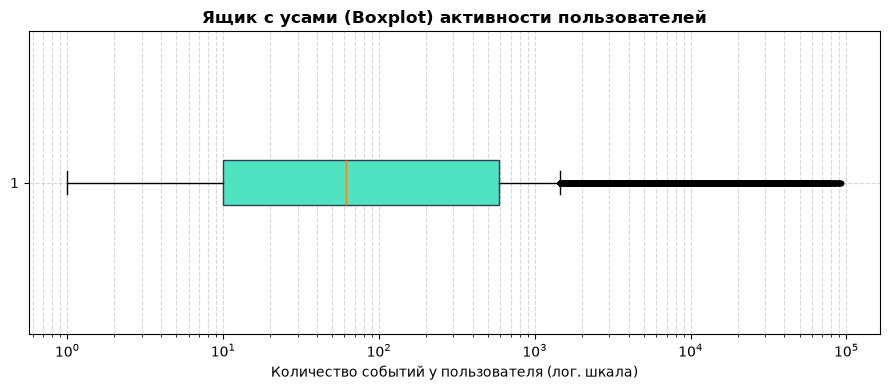

In [137]:
plt.figure(figsize=(9, 4))
plt.boxplot(counts, orientation='horizontal', patch_artist=True,
            boxprops=dict(facecolor='#50E3C2', color='#2C3E50'),
            flierprops=dict(marker='o', color='red', alpha=0.3, markersize=3))

plt.title('Ящик с усами (Boxplot) активности пользователей', fontsize=12, fontweight='bold')
plt.xlabel('Количество событий у пользователя (лог. шкала)')
plt.xscale('log')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [138]:
daily_aggregates = []

for i, file_name in enumerate(events_files):
    file_path = os.path.join(events_path, file_name)

    df_day = pl.read_parquet(file_path, columns=["item_id", "action_type"])

    df_orders = (
        df_day
        .filter(pl.col("action_type") == "order")
        .join(df_retail, on="item_id", how="inner") # inner join сразу отсекает сироты без каталога!
        .group_by("subcategory")
        .len(name="order_count")
    )

    daily_aggregates.append(df_orders)

final_subcat_orders = (
    pl.concat(daily_aggregates)
    .group_by("subcategory")
    .agg(pl.col("order_count").sum())
    .sort("order_count", descending=True)
)

print("Топ подкатегорий по количеству заказов:")
print(final_subcat_orders.head(10))

Топ подкатегорий по количеству заказов:
shape: (10, 2)
┌─────────────────────────────────┬─────────────┐
│ subcategory                     ┆ order_count │
│ ---                             ┆ ---         │
│ str                             ┆ u32         │
╞═════════════════════════════════╪═════════════╡
│ Fresh Vegetables, Fruits, and … ┆ 1129675     │
│ Dairy Products and Eggs         ┆ 1036305     │
│ Sweet Desserts and Confectione… ┆ 487262      │
│ Storage and Transport Containe… ┆ 425170      │
│ Ready-to-Eat Food Products      ┆ 384452      │
│ Bakery Products                 ┆ 376503      │
│ Beverages and Drinks            ┆ 373039      │
│ Frozen Food Products            ┆ 356921      │
│ Meat, Poultry, and Semi-Finish… ┆ 321812      │
│ Grains, Pasta, and Flour Produ… ┆ 305104      │
└─────────────────────────────────┴─────────────┘


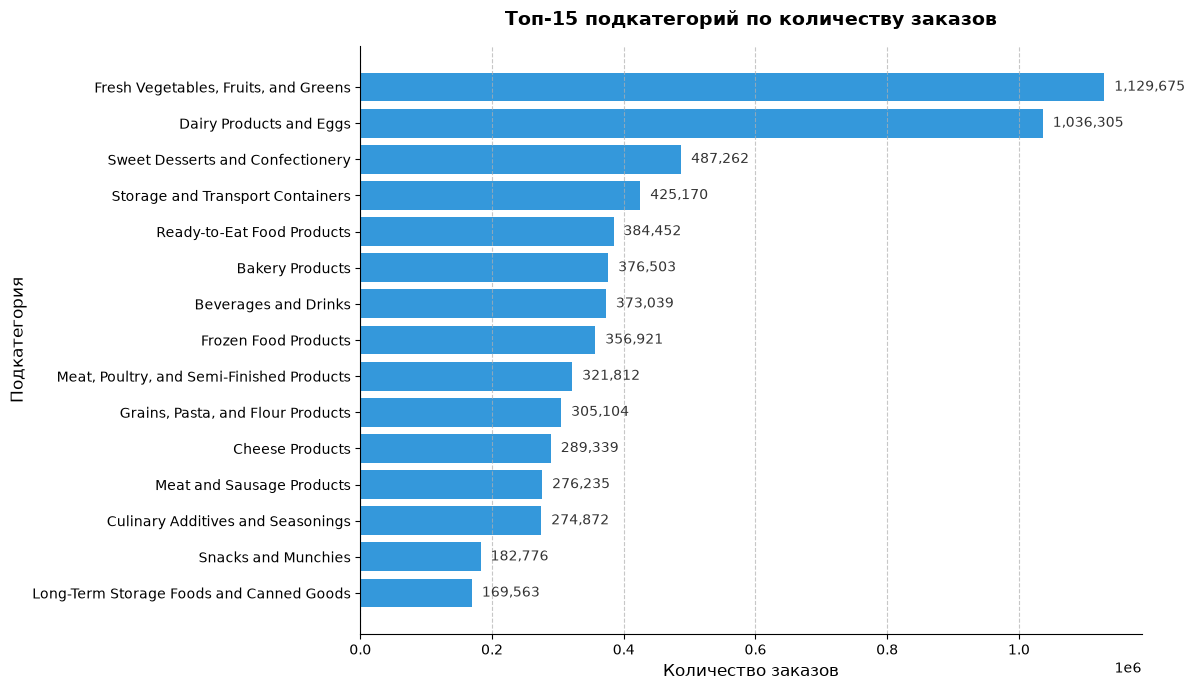

In [139]:
df_top15 = final_subcat_orders.head(15)
subcategories = df_top15.get_column("subcategory").to_list()
counts = df_top15.get_column("order_count").to_list()

plt.figure(figsize=(12, 7))

bars = plt.barh(subcategories[::-1], counts[::-1], color="#3498db")

plt.title("Топ-15 подкатегорий по количеству заказов", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Количество заказов", fontsize=12)
plt.ylabel("Подкатегория", fontsize=12)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 15000,  # небольшой отступ вправо от бара
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        ha="left",
        fontsize=10,
        color="#333333"
    )

# Убираем лишние рамки для чистоты стиля
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

В категории retail базовые продукты питания составляют большинство покупок. Для анализа и кластеризации пользователй на кошатников и родителей нужно исключать повседневные продукты, хлеб и яйца из тренировочных данных.


## 5. RecSys EDA

In [140]:
target_subcat = [
    "Dairy Products and Eggs",
    "Fresh Vegetables, Fruits, and Greens"
]
base_item_ids = set(
    df_retail.filter(pl.col("subcategory").is_in(target_subcat))
    .get_column("item_id")
    .to_list()
)

print(f"Товаров в категории '{", ".join(target_subcat)}': {len(base_item_ids):,}")

# 2. Сканируем события заказов по всем файлам и считаем уникальных юзеров
events_pattern = os.path.join(DATASET_PATH, 'retail', 'events', '*.pq')
lazy_events = pl.scan_parquet(events_pattern)

# Общее количество уникальных пользователей во всем логе
total_users_count = lazy_events.select("user_id").unique().collect().height

# Пользователи, которые совершили хотя бы один order в этой базовой категории
users_bought_base = (
    lazy_events
    .filter((pl.col("action_type") == "order") & (pl.col("item_id").is_in(base_item_ids)))
    .select("user_id")
    .unique()
    .collect()
    .height
)

pct_buying = (users_bought_base / total_users_count) * 100
print(f"Всего пользователей в логах: {total_users_count:,}")
print(f"Покупали товары из '{", ".join(target_subcat)}': {users_bought_base:,} ({pct_buying:.2f}%)")

Товаров в категории 'Dairy Products and Eggs, Fresh Vegetables, Fruits, and Greens': 26,382


Всего пользователей в логах: 140,062
Покупали товары из 'Dairy Products and Eggs, Fresh Vegetables, Fruits, and Greens': 56,235 (40.15%)


Только 40% пользователей оформляли заказы на молочку, яйца, овощи и фрукты.

Почти 60% аудитории в логах используют сервис для других целей, например:

* Зоотовары (Cat Supplies, Dog Supplies, Rodent and Ferret Supplies, Bird Supplies)

* Детские товары (Diapers and Hygiene Products, Creative Kits for Children, Infant Clothing)

* Бытовая техника и электроника (Mobile Devices and Electronic Accessories, Compact Kitchen Appliances)

* Автотовары, ремонт, спорт и даже литература (Car Parts, Construction and Repair Materials, Literary Fiction Works)


In [141]:
item_order_popularity = (
    lazy_events
    .filter(pl.col("action_type") == "order")
    .group_by("item_id")
    .len(name="orders_count")
    .sort("orders_count", descending=True)
    .collect()
)

total_items = item_order_popularity.height

item_order_popularity = item_order_popularity.with_columns(
    cumulative_orders_pct=(pl.col("orders_count").cum_sum() / pl.col("orders_count").sum()) * 100,
    item_rank_pct=((pl.int_range(0, pl.len(), dtype=pl.UInt32) + 1) / total_items) * 100
)

In [142]:
top_items_with_subcat = (
    item_order_popularity
    .join(df_retail.select(["item_id", "subcategory"]), on="item_id", how="left")
    .select(["item_id", "subcategory", "orders_count", "cumulative_orders_pct", "item_rank_pct"])
)

print(top_items_with_subcat.head(15))

shape: (15, 5)
┌──────────────┬────────────────────────────┬──────────────┬───────────────────────┬───────────────┐
│ item_id      ┆ subcategory                ┆ orders_count ┆ cumulative_orders_pct ┆ item_rank_pct │
│ ---          ┆ ---                        ┆ ---          ┆ ---                   ┆ ---           │
│ str          ┆ str                        ┆ u32          ┆ f64                   ┆ f64           │
╞══════════════╪════════════════════════════╪══════════════╪═══════════════════════╪═══════════════╡
│ fmcg_180861  ┆ Storage and Transport      ┆ 315010       ┆ 4.237582              ┆ 0.000702      │
│              ┆ Containe…                  ┆              ┆                       ┆               │
│ fmcg_66926   ┆ Storage and Transport      ┆ 77677        ┆ 5.282509              ┆ 0.001404      │
│              ┆ Containe…                  ┆              ┆                       ┆               │
│ fmcg_335947  ┆ Fresh Vegetables, Fruits,  ┆ 23842        ┆ 5.603237       

Топовые товары:

* Storage and Transport Containers - ваш любимый товар - Пакет

* Fresh Vegetables, Fruits, and Greens - видимо картофель, морковь и лук.

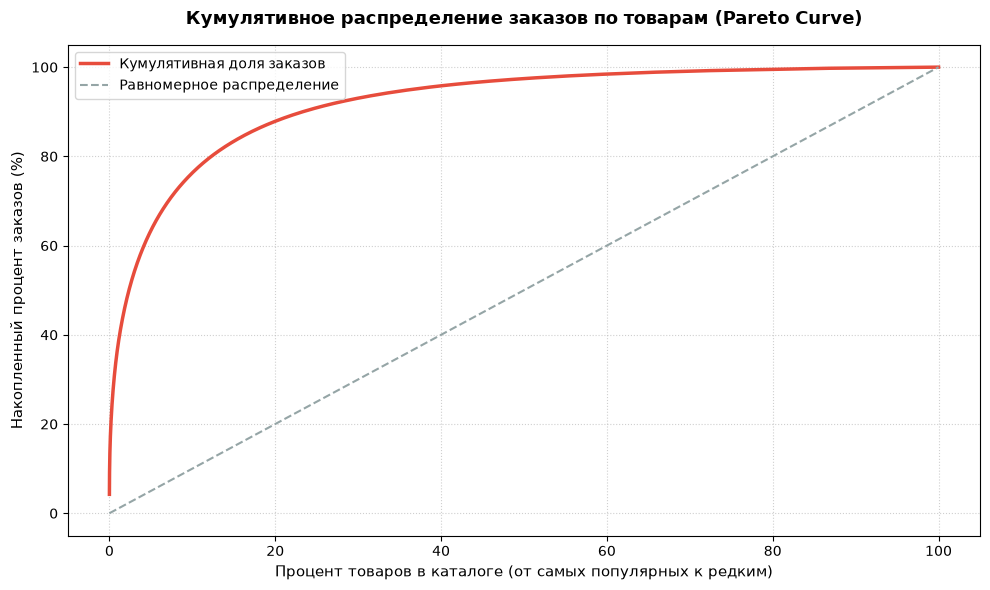

In [143]:
x = item_order_popularity.get_column("item_rank_pct").to_numpy()
y = item_order_popularity.get_column("cumulative_orders_pct").to_numpy()

plt.figure(figsize=(10, 6))
plt.plot(x, y, color="#e74c3c", linewidth=2.5, label="Кумулятивная доля заказов")

plt.plot([0, 100], [0, 100], color="#95a5a6", linestyle="--", label="Равномерное распределение")

plt.title("Кумулятивное распределение заказов по товарам (Pareto Curve)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Процент товаров в каталоге (от самых популярных к редким)", fontsize=11)
plt.ylabel("Накопленный процент заказов (%)", fontsize=11)

plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

График показывает - ~15% товаров дают 80% покупок, ~25% - 90% покупок. 

Судя по популярности категорий, большинство пользователей выбирают хлеб и лук.
Из за этого у нас есть длинный хвост редких покупок, вроде пачки соды, что нужно учесть при тренировке модели.

## 6. Другие домены

### 6.1. marketplace

In [144]:
df_marketplace_items = pl.read_parquet(os.path.join(DATASET_PATH, 'marketplace', 'items.pq'))
print(df_marketplace_items.head(3))
print(f"Всего продуктов в таблице: {len(df_marketplace_items)}")

shape: (3, 6)
┌────────────────┬──────────┬──────────────┬─────────────────────┬───────────┬─────────────────────┐
│ item_id        ┆ brand_id ┆ category     ┆ subcategory         ┆ price     ┆ embedding           │
│ ---            ┆ ---      ┆ ---          ┆ ---                 ┆ ---       ┆ ---                 │
│ str            ┆ u64      ┆ str          ┆ str                 ┆ f64       ┆ array[f32, 300]     │
╞════════════════╪══════════╪══════════════╪═════════════════════╪═══════════╪═════════════════════╡
│ nfmcg_10000001 ┆ 137356   ┆ null         ┆ null                ┆ 6.06364   ┆ [-0.070853,         │
│                ┆          ┆              ┆                     ┆           ┆ 0.03246, … 0.08217… │
│ nfmcg_10000012 ┆ 53389    ┆ null         ┆ null                ┆ 0.960436  ┆ [-0.091099,         │
│                ┆          ┆              ┆                     ┆           ┆ 0.043168, … 0.0602… │
│ nfmcg_1000002  ┆ 34153    ┆ Fashion      ┆ Hats, Scarves, and  ┆ -1.793113 

In [145]:
marketplace_events_pattern = os.path.join(DATASET_PATH, 'marketplace', 'events', '*.pq')
marketplace_events_path = os.path.join(DATASET_PATH, 'marketplace', 'events')
marketplace_events_files = sorted(os.listdir(events_path))
total_marketplace_events_files = len(marketplace_events_files)

print(f"Всего файлов в папке events: {total_marketplace_events_files}")

Всего файлов в папке events: 227


In [146]:
df_marketplace_first = pl.read_parquet(os.path.join(DATASET_PATH, 'marketplace', 'events', marketplace_events_files[0]))
print(df_marketplace_first.head(3))
print(f"Данные за один день: {len(df_marketplace_first)}")

shape: (3, 6)
┌────────────────┬──────────┬────────────────┬───────────┬─────────────┬─────────┐
│ timestamp      ┆ user_id  ┆ item_id        ┆ subdomain ┆ action_type ┆ os      │
│ ---            ┆ ---      ┆ ---            ┆ ---       ┆ ---         ┆ ---     │
│ duration[μs]   ┆ u64      ┆ str            ┆ str       ┆ str         ┆ str     │
╞════════════════╪══════════╪════════════════╪═══════════╪═════════════╪═════════╡
│ 1082d 89901µs  ┆ 59328774 ┆ nfmcg_14777696 ┆ u2i       ┆ view        ┆ android │
│ 1082d 163483µs ┆ 66295302 ┆ nfmcg_26098539 ┆ catalog   ┆ view        ┆ android │
│ 1082d 864625µs ┆ 37542104 ┆ nfmcg_10840247 ┆ u2i       ┆ view        ┆ android │
└────────────────┴──────────┴────────────────┴───────────┴─────────────┴─────────┘
Данные за один день: 500002


In [147]:
retail_users = (
    pl.scan_parquet(events_pattern)
    .select("user_id")
    .unique()
    .collect()
    .get_column("user_id")
)

retail_user_set = set(retail_users.to_list())
print(f"Уникальных пользователей в Retail: {len(retail_user_set):,}")

marketplace_users = (
    pl.scan_parquet(marketplace_events_pattern)
    .select("user_id")
    .unique()
    .collect()
    .get_column("user_id")
)

marketplace_user_set = set(marketplace_users.to_list())
print(f"Уникальных пользователей в Marketplace: {len(marketplace_user_set):,}")

# 3. Считаем пересечение (интерсекцию)
intersection_users = retail_user_set.intersection(marketplace_user_set)
print(f"Пересекающихся пользователей (оба домена): {len(intersection_users):,}")
print(f"Доля пересечения от Retail: {len(intersection_users) / len(retail_user_set) * 100:.2f}%")
print(f"Доля пересечения от Marketplace: {len(intersection_users) / len(marketplace_user_set) * 100:.2f}%")

Уникальных пользователей в Retail: 140,062
Уникальных пользователей в Marketplace: 1,616,763
Пересекающихся пользователей (оба домена): 127,080
Доля пересечения от Retail: 90.73%
Доля пересечения от Marketplace: 7.86%


Практически 91% процент пользователей ретейла присутствует в маркетлейса. Значит мы можем выявить кластеры пользователей в ритейле, а потом рекомендовать им товары из маркетплейса

### 6.2. offers

In [148]:
df_offers_items = pl.read_parquet(os.path.join(DATASET_PATH, 'offers', 'items.pq'))
print(df_offers_items.head(3))
print(f"Всего предложений в таблице: {len(df_offers_items)}")

shape: (3, 3)
┌─────────────┬──────────┬─────────────────────────────────┐
│ item_id     ┆ brand_id ┆ embedding                       │
│ ---         ┆ ---      ┆ ---                             │
│ str         ┆ u64      ┆ array[f32, 312]                 │
╞═════════════╪══════════╪═════════════════════════════════╡
│ offer_1000  ┆ 25974    ┆ [0.012451, -0.006554, … -0.104… │
│ offer_10001 ┆ 233535   ┆ [0.084303, 0.004278, … -0.1099… │
│ offer_10010 ┆ 237081   ┆ [0.02631, 0.07163, … -0.004321… │
└─────────────┴──────────┴─────────────────────────────────┘
Всего предложений в таблице: 22368


In [149]:
offers_events_pattern = os.path.join(DATASET_PATH, 'offers', 'events', '*.pq')
offers_events_path = os.path.join(DATASET_PATH, 'offers', 'events')
offers_events_files = sorted(os.listdir(events_path))
total_offers_events_files = len(offers_events_files)

print(f"Всего файлов в папке events: {total_offers_events_files}")

Всего файлов в папке events: 227


In [150]:
df_offers_first = pl.read_parquet(os.path.join(DATASET_PATH, 'offers', 'events', offers_events_files[0]))
print(df_offers_first.head(3))
print(f"Данные за один день: {len(df_offers_first)}")

shape: (3, 4)
┌────────────────┬──────────┬─────────────┬─────────────┐
│ timestamp      ┆ user_id  ┆ item_id     ┆ action_type │
│ ---            ┆ ---      ┆ ---         ┆ ---         │
│ duration[μs]   ┆ u64      ┆ str         ┆ str         │
╞════════════════╪══════════╪═════════════╪═════════════╡
│ 1082d 126754µs ┆ 20110833 ┆ offer_83661 ┆ view        │
│ 1082d 143308µs ┆ 36541803 ┆ offer_81670 ┆ view        │
│ 1082d 157553µs ┆ 34286733 ┆ offer_42637 ┆ view        │
└────────────────┴──────────┴─────────────┴─────────────┘
Данные за один день: 2572392


In [151]:
offers_users = set(
    pl.scan_parquet(offers_events_pattern)
    .select("user_id")
    .unique()
    .collect()
    .get_column("user_id")
    .to_list()
)

print(f"Пользователей в Retail: {len(retail_user_set):,}")
print(f"Пользователей в Offers: {len(offers_users):,}")

# 3. Считаем пересечение
intersection_offers = retail_user_set.intersection(offers_users)
print(f"Пересечение (Retail & Offers): {len(intersection_offers):,}")
print(f"Доля от Retail: {len(intersection_offers) / len(retail_user_set) * 100:.2f}%")

Пользователей в Retail: 140,062
Пользователей в Offers: 2,216,762
Пересечение (Retail & Offers): 138,847
Доля от Retail: 99.13%


99% пользователей получали персональные предложения, значит мы можем проанализировать как пользователь реагирует на новые офферы.

### 6.3. reviews

In [152]:
reviews_events_pattern = os.path.join(DATASET_PATH, 'reviews', '*.pq')
reviews_events_path = os.path.join(DATASET_PATH, 'reviews')
reviews_events_files = sorted(os.listdir(events_path))
total_reviews_events_files = len(reviews_events_files)

print(f"Всего файлов в папке reviews: {total_reviews_events_files}")

Всего файлов в папке reviews: 227


In [153]:
df_reviews_first = pl.read_parquet(os.path.join(DATASET_PATH, 'reviews', reviews_events_files[0]))
print(df_reviews_first.head(3))
print(f"Данные за один день: {len(df_reviews_first)}")

shape: (3, 6)
┌───────────────────────┬──────────┬──────────┬────────┬──────┬─────────────────┐
│ timestamp             ┆ user_id  ┆ brand_id ┆ rating ┆ text ┆ embedding       │
│ ---                   ┆ ---      ┆ ---      ┆ ---    ┆ ---  ┆ ---             │
│ duration[μs]          ┆ u64      ┆ u64      ┆ u8     ┆ str  ┆ array[f32, 312] │
╞═══════════════════════╪══════════╪══════════╪════════╪══════╪═════════════════╡
│ 1082d 1m 5s 711723µs  ┆ 25741061 ┆ 141226   ┆ 5      ┆ null ┆ null            │
│ 1082d 1m 12s 26501µs  ┆ 71011848 ┆ 65693    ┆ 3      ┆ null ┆ null            │
│ 1082d 2m 15s 540704µs ┆ 26101012 ┆ 72285    ┆ 5      ┆ null ┆ null            │
└───────────────────────┴──────────┴──────────┴────────┴──────┴─────────────────┘
Данные за один день: 2439


In [154]:
reviews_users = set(
    pl.scan_parquet(reviews_events_pattern)
    .select("user_id")
    .unique()
    .collect()
    .get_column("user_id")
    .to_list()
)

print(f"Пользователей в Retail: {len(retail_user_set):,}")
print(f"Пользователей в Offers: {len(reviews_users):,}")

# 3. Считаем пересечение
intersection_reviews = retail_user_set.intersection(reviews_users)
print(f"Пересечение (Retail & Offers): {len(intersection_reviews):,}")
print(f"Доля от Retail: {len(intersection_reviews) / len(retail_user_set) * 100:.2f}%")

Пользователей в Retail: 140,062
Пользователей в Offers: 103,834
Пересечение (Retail & Offers): 14,675
Доля от Retail: 10.48%


Только 10% пользовтелей retail оставили отзывы. Большинство пользователей заказывают продукты но не оставляют отзывов.

## 7. Выводы

* Высокое качество датасета. Пропусков очень мало, пропущенных эмбедингов в товарах нет, что позволит произвести анализ без категорий и подкатегорий. Все товары из событий имеют бренд из таблицы brands, и все пользователи есть в таблице users. Дубликаты в событиях не внесут искажений в работу модели. Есть дубликаты в бренда, нужно усреднить эмбединги.

* Большое кол-во событий у пользователей - 92 615 выглядит подозрительно. Необходимо отфильтровывать пользователей с подозрительно большой активностью.

* Есть товары на долю которых приходится 320 414 событий а есть товары на долю которых приходится 1 событие. ~15% товаров занимают 80% покупок. Базовые продукты питания составляют большинство покупок. Для анализа и кластеризации пользователй на кошатников и родителей нужно исключать повседневные продукты, хлеб, картофель и яйца из данных.

* Особенность покупок в Retail - покупок больше чем кликов и добавлений в корзину. Строить классическую продуктовую воронку конверсий (view -> click -> cart -> order) по этим цифрам бесполезно и некорректно.

* 91% пользователей ритейла присутствуют в маркетплейсе и 99% реагируют на специальные предложения, что дает возможность кросс доменных рекомендаций. Только 10% пользователей ритейла оставляют отзывы, что осложняет анализ, но можно использовать отзывы на бренды.
